<a href="https://colab.research.google.com/github/MacUpr/ML/blob/main/BaseDeDados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Preparação do ambiente

> **Nota para o professor:** em Colab, prefira ativar GPU em `Ambiente de execução > Alterar tipo de ambiente de execução > T4 GPU`.

In [ ]:
!pip -q install datasets transformers sentence-transformers

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import IsolationForest

from pandas.plotting import parallel_coordinates

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)

# 1. EDA em dados tabulares: Wine

## Pergunta

**As características químicas dos vinhos formam padrões compatíveis com suas classes?**

Essa pergunta deve orientar toda a exploração.

In [ ]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
df_wine = wine.frame.copy()
df_wine["class_name"] = df_wine["target"].map(dict(enumerate(wine.target_names)))

df_wine.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


### 1.1 Unidade de análise e estrutura

Antes de calcular qualquer estatística, responda:

- O que representa cada linha?
- O que representa cada coluna?
- Qual é a variável de classe?
- Quais atributos são numéricos?

Precisamos da descrição do [dataset](https://archive.ics.uci.edu/dataset/109/wine)

In [ ]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
print(wine.DESCR)

NameError: name 'wine' is not defined

In [ ]:
print("Dimensão:", df_wine.shape)
print("\nColunas:")
print(df_wine.columns.tolist())
print("\nTipos:")
print(df_wine.dtypes)

Dimensão: (178, 15)

Colunas:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target', 'class_name']

Tipos:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
class_name                       object
dtype: object


### 1.2 Perfil inicial

> **Pergunta:** o que `describe()` consegue responder? E o que ele não consegue?

In [ ]:
display(df_wine.describe().T)

print("Distribuição das classes:")
display(df_wine["class_name"].value_counts())

print("\nValores ausentes:")
display(df_wine.isna().sum().sort_values(ascending=False).head())

print("\nDuplicatas:")
print(df_wine.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Distribuição das classes:


,count
class_name,
class_1,71
class_0,59
class_2,48



Valores ausentes:


,0
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0



Duplicatas:
0


- `describe()` descreve cada variável numericamente. Ele não explica a **estrutura dos dados**.
- distribuição, relação entre atributos, classes, outliers etc.

### 1.3 Distribuições e outliers

> Vamos discretizar os atributos em intervalos fixos de 20 valores (bins) e calcular a frequencia de valores em cada intervalo. Isso faz com que diminuimos a quantidade de valores do atributo por exemplo de 178 valores diferentes para 20 valores.


Bins da variável: alcohol
Bin  1: [11.03, 11.22) → 1 amostras
Bin  2: [11.22, 11.41) → 0 amostras
Bin  3: [11.41, 11.60) → 4 amostras
Bin  4: [11.60, 11.79) → 6 amostras
Bin  5: [11.79, 11.98) → 8 amostras
Bin  6: [11.98, 12.17) → 11 amostras
Bin  7: [12.17, 12.36) → 14 amostras
Bin  8: [12.36, 12.55) → 17 amostras
Bin  9: [12.55, 12.74) → 10 amostras
Bin 10: [12.74, 12.93) → 11 amostras
Bin 11: [12.93, 13.12) → 15 amostras
Bin 12: [13.12, 13.31) → 12 amostras
Bin 13: [13.31, 13.50) → 12 amostras
Bin 14: [13.50, 13.69) → 13 amostras
Bin 15: [13.69, 13.88) → 18 amostras
Bin 16: [13.88, 14.07) → 7 amostras
Bin 17: [14.07, 14.26) → 11 amostras
Bin 18: [14.26, 14.45) → 6 amostras
Bin 19: [14.45, 14.64) → 0 amostras
Bin 20: [14.64, 14.83) → 2 amostras


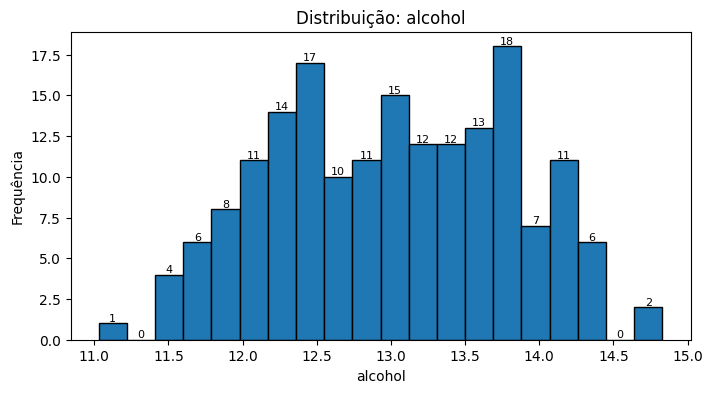


Bins da variável: malic_acid
Bin  1: [0.74, 0.99) → 8 amostras
Bin  2: [0.99, 1.25) → 10 amostras
Bin  3: [1.25, 1.50) → 15 amostras
Bin  4: [1.50, 1.75) → 44 amostras
Bin  5: [1.75, 2.00) → 23 amostras
Bin  6: [2.00, 2.26) → 10 amostras
Bin  7: [2.26, 2.51) → 8 amostras
Bin  8: [2.51, 2.76) → 8 amostras
Bin  9: [2.76, 3.02) → 5 amostras
Bin 10: [3.02, 3.27) → 9 amostras
Bin 11: [3.27, 3.52) → 5 amostras
Bin 12: [3.52, 3.78) → 6 amostras
Bin 13: [3.78, 4.03) → 10 amostras
Bin 14: [4.03, 4.28) → 4 amostras
Bin 15: [4.28, 4.54) → 4 amostras
Bin 16: [4.54, 4.79) → 3 amostras
Bin 17: [4.79, 5.04) → 2 amostras
Bin 18: [5.04, 5.29) → 1 amostras
Bin 19: [5.29, 5.55) → 1 amostras
Bin 20: [5.55, 5.80) → 2 amostras


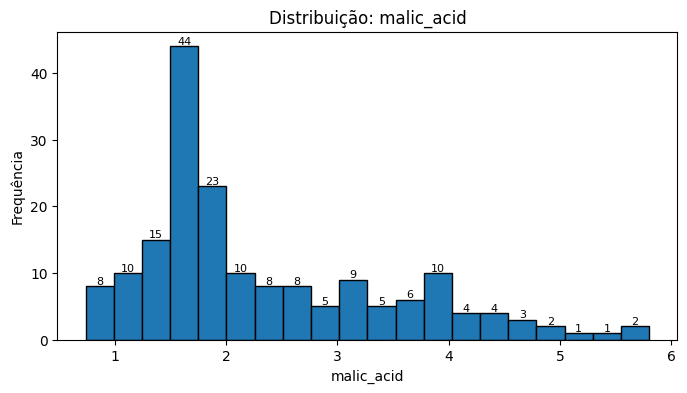


Bins da variável: magnesium
Bin  1: [70.00, 74.60) → 1 amostras
Bin  2: [74.60, 79.20) → 3 amostras
Bin  3: [79.20, 83.80) → 7 amostras
Bin  4: [83.80, 88.40) → 36 amostras
Bin  5: [88.40, 93.00) → 16 amostras
Bin  6: [93.00, 97.60) → 24 amostras
Bin  7: [97.60, 102.20) → 29 amostras
Bin  8: [102.20, 106.80) → 14 amostras
Bin  9: [106.80, 111.40) → 14 amostras
Bin 10: [111.40, 116.00) → 10 amostras
Bin 11: [116.00, 120.60) → 11 amostras
Bin 12: [120.60, 125.20) → 4 amostras
Bin 13: [125.20, 129.80) → 3 amostras
Bin 14: [129.80, 134.40) → 2 amostras
Bin 15: [134.40, 139.00) → 1 amostras
Bin 16: [139.00, 143.60) → 1 amostras
Bin 17: [143.60, 148.20) → 0 amostras
Bin 18: [148.20, 152.80) → 1 amostras
Bin 19: [152.80, 157.40) → 0 amostras
Bin 20: [157.40, 162.00) → 1 amostras


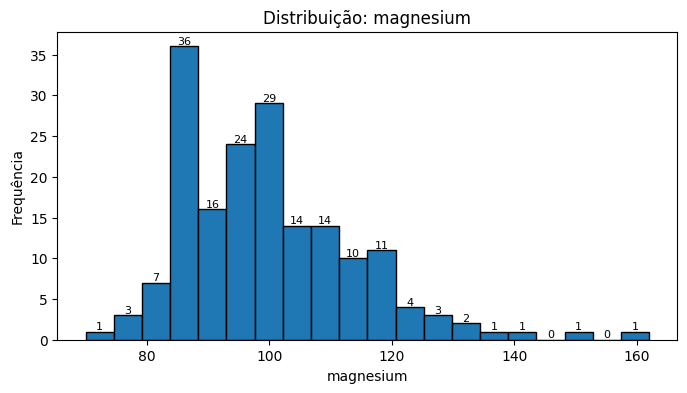


Bins da variável: color_intensity
Bin  1: [1.28, 1.87) → 2 amostras
Bin  2: [1.87, 2.45) → 14 amostras
Bin  3: [2.45, 3.04) → 23 amostras
Bin  4: [3.04, 3.62) → 19 amostras
Bin  5: [3.62, 4.21) → 15 amostras
Bin  6: [4.21, 4.80) → 17 amostras
Bin  7: [4.80, 5.38) → 18 amostras
Bin  8: [5.38, 5.97) → 20 amostras
Bin  9: [5.97, 6.55) → 9 amostras
Bin 10: [6.55, 7.14) → 8 amostras
Bin 11: [7.14, 7.73) → 10 amostras
Bin 12: [7.73, 8.31) → 3 amostras
Bin 13: [8.31, 8.90) → 5 amostras
Bin 14: [8.90, 9.48) → 5 amostras
Bin 15: [9.48, 10.07) → 3 amostras
Bin 16: [10.07, 10.66) → 3 amostras
Bin 17: [10.66, 11.24) → 2 amostras
Bin 18: [11.24, 11.83) → 1 amostras
Bin 19: [11.83, 12.41) → 0 amostras
Bin 20: [12.41, 13.00) → 1 amostras


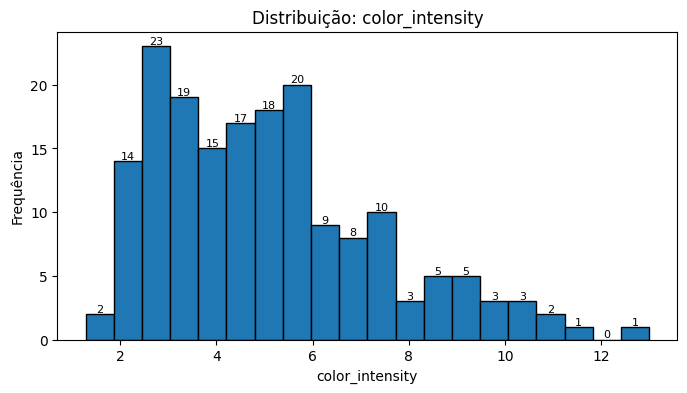


Bins da variável: proline
Bin  1: [278.00, 348.10) → 8 amostras
Bin  2: [348.10, 418.20) → 14 amostras
Bin  3: [418.20, 488.30) → 18 amostras
Bin  4: [488.30, 558.40) → 19 amostras
Bin  5: [558.40, 628.50) → 19 amostras
Bin  6: [628.50, 698.60) → 22 amostras
Bin  7: [698.60, 768.70) → 12 amostras
Bin  8: [768.70, 838.80) → 7 amostras
Bin  9: [838.80, 908.90) → 9 amostras
Bin 10: [908.90, 979.00) → 4 amostras
Bin 11: [979.00, 1049.10) → 10 amostras
Bin 12: [1049.10, 1119.20) → 9 amostras
Bin 13: [1119.20, 1189.30) → 5 amostras
Bin 14: [1189.30, 1259.40) → 3 amostras
Bin 15: [1259.40, 1329.50) → 12 amostras
Bin 16: [1329.50, 1399.60) → 1 amostras
Bin 17: [1399.60, 1469.70) → 1 amostras
Bin 18: [1469.70, 1539.80) → 3 amostras
Bin 19: [1539.80, 1609.90) → 1 amostras
Bin 20: [1609.90, 1680.00) → 1 amostras


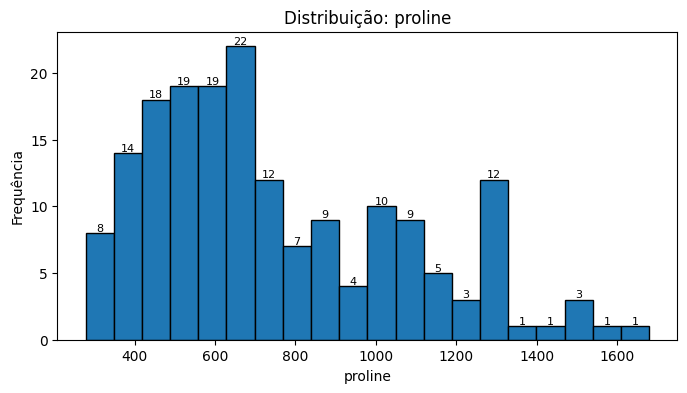

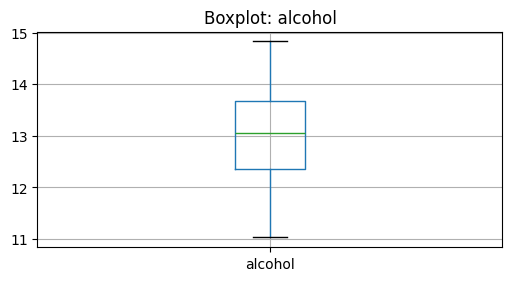

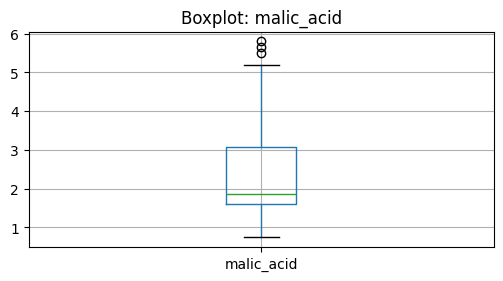

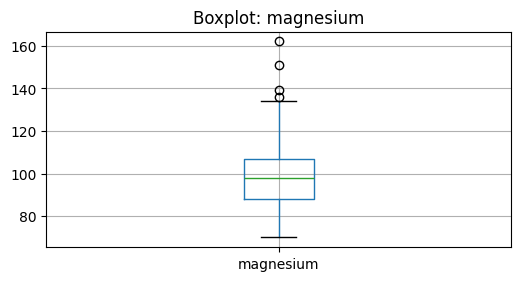

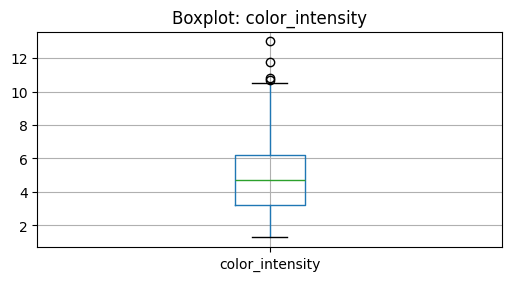

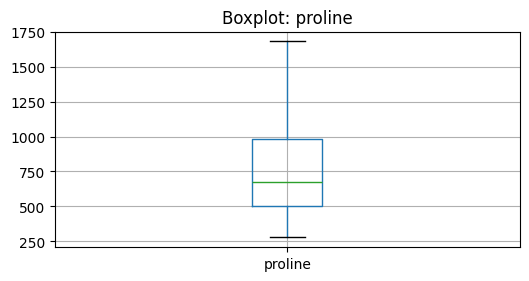

In [ ]:
features_to_plot = ["alcohol", "malic_acid", "magnesium", "color_intensity", "proline"]

for col in features_to_plot:
    plt.figure(figsize=(8,4))

    counts, bins, patches = plt.hist(
        df_wine[col],
        bins=20,
        edgecolor="black"
    )

    for count, patch in zip(counts, patches):
        plt.text(
            patch.get_x() + patch.get_width()/2,
            count,
            str(int(count)),
            ha="center",
            va="bottom",
            fontsize=8
        )

    # Imprimir os intervalos e frequências
    print(f"\nBins da variável: {col}")

    for i in range(len(counts)):
        print(
            f"Bin {i+1:2d}: "
            f"[{bins[i]:.2f}, {bins[i+1]:.2f}) "
            f"→ {int(counts[i])} amostras"
        )
    plt.title(f"Distribuição: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequência")
    plt.show()

for col in features_to_plot:
    plt.figure(figsize=(6,2.8))
    df_wine.boxplot(column=col)
    plt.title(f"Boxplot: {col}")
    plt.suptitle("")
    plt.show()

### 1.4 Parallel coordinates

Como as escalas das features são muito diferentes, padronizamos antes. Essa padronização visa alterar a escala dos valores dos atributos para evitar que determinados atributos tenham valores que dominem outros atributos. Todos os atributos agora estão variando de -4 a +4.

> **Pergunta:** quais atributos parecem mostrar padrões diferentes entre as classes?

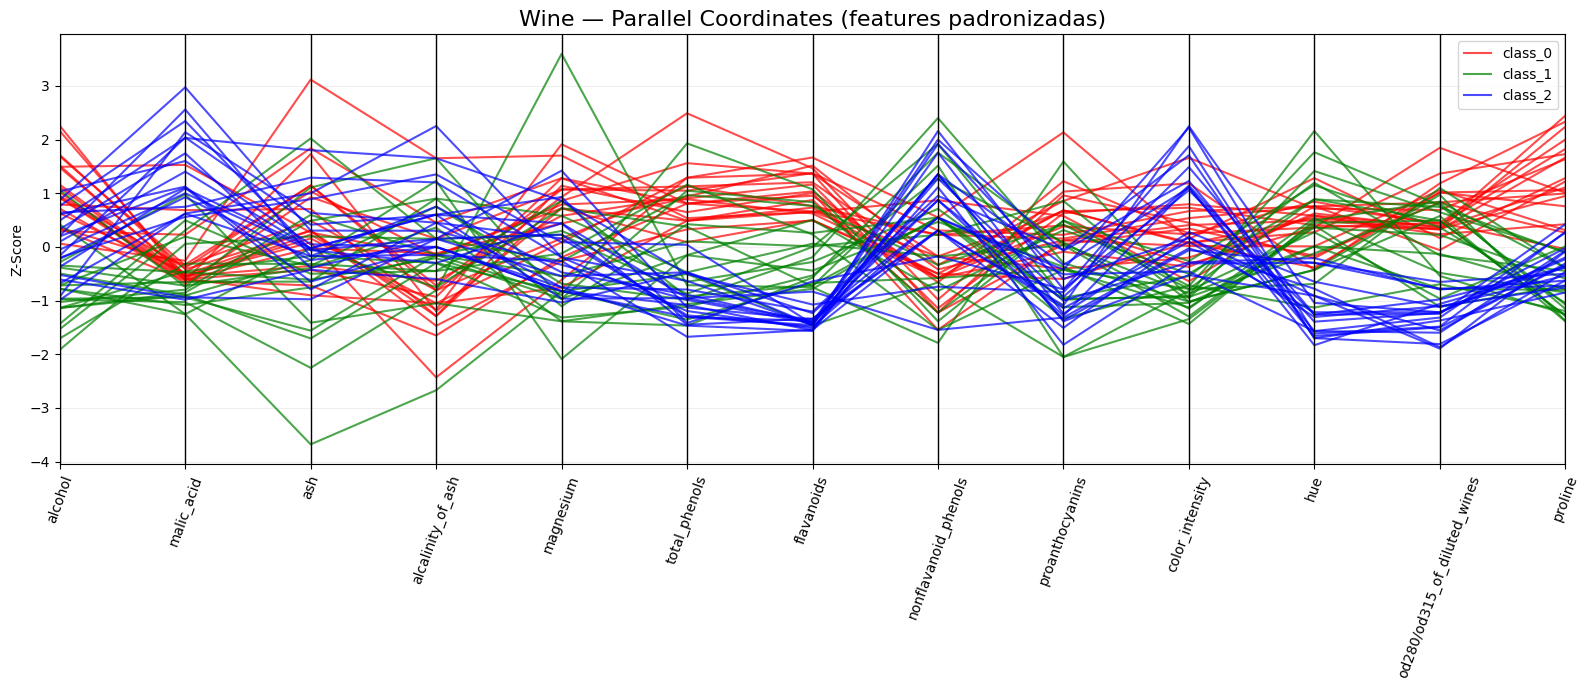

In [ ]:
  feature_cols = wine.feature_names

# Padronização Z-Score
X_scaled = StandardScaler().fit_transform(df_wine[feature_cols])

df_parallel = pd.DataFrame(X_scaled, columns=feature_cols)
df_parallel["class_name"] = df_wine["class_name"].values

# Amostrar 20 exemplos de cada classe
parts = []

for class_name, group in df_parallel.groupby("class_name"):
    parts.append(
        group.sample(
            min(len(group), 20),
            random_state=RANDOM_STATE
        )
    )

sample_parallel = pd.concat(parts).reset_index(drop=True)


# Parallel Coordinates
plt.figure(figsize=(16, 7))

parallel_coordinates(
    sample_parallel,
    class_column="class_name",
    color=["red", "green", "blue"],
    alpha=0.70,       # menos transparente
    linewidth=1.5     # linhas mais espessas
)

plt.xticks(rotation=70)
plt.title(
    "Wine — Parallel Coordinates (features padronizadas)",
    fontsize=16
)

plt.ylabel("Z-Score")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Discussão

- Existem features visualmente mais discriminativas?
- Existem regiões de forte sobreposição?
- Um gráfico como este é suficiente para concluir que as classes são separáveis?
- O que acontece quando temos centenas de dimensões?

# 2. Qualidade dos dados: vamos sabotar a base

Bases didáticas costumam ser limpas demais. Em projetos reais encontramos:

- valores ausentes;
- duplicatas;
- tipos incorretos;
- categorias inconsistentes;
- ruído;
- outliers.

In [ ]:
df_dirty = df_wine.copy()

# Missing values artificiais
for col in ["alcohol", "malic_acid", "magnesium"]:
    idx = np.random.choice(df_dirty.index, size=5, replace=False)
    df_dirty.loc[idx, col] = np.nan

# Duplicatas
df_dirty = pd.concat([df_dirty, df_dirty.iloc[:5]], ignore_index=True)

# Outliers artificiais
df_dirty.loc[0, "magnesium"] = df_dirty["magnesium"].median() * 8
df_dirty.loc[1, "color_intensity"] = df_dirty["color_intensity"].median() * 10
print("Outliers nas linhas: 0 e 1")

# Ruído em uma feature
noise_idx = np.random.choice(df_dirty.index, size=10, replace=False)
print("Ruído nas linhas:", noise_idx)
df_dirty.loc[noise_idx, "proline"] += np.random.normal(0, 800, size=10)

print("Shape após sabotagem:", df_dirty.shape)

Outliers nas linhas: 0 e 1
Ruído nas linhas: [120 163  39 126 134  67  65 161  78  92]
Shape após sabotagem: (183, 15)


In [ ]:
print("Valores ausentes:")
display(df_dirty.isna().sum().sort_values(ascending=False).head(10))

print("\nDuplicatas:")
print(df_dirty.duplicated().sum())

print("\nResumo:")
display(df_dirty.describe().T)

Valores ausentes:


,0
alcohol,5
malic_acid,5
magnesium,5
ash,0
alcalinity_of_ash,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0



Duplicatas:
3

Resumo:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.008034,0.814235,11.030000,12.3625,13.05,13.6775,14.830000
malic_acid,178.0,2.343539,1.105103,0.740000,1.6150,1.87,3.0300,5.800000
ash,183.0,2.370765,0.274736,1.360000,2.2100,2.36,2.5600,3.230000
alcalinity_of_ash,183.0,19.416940,3.370213,10.600000,17.0500,19.40,21.5000,30.000000
magnesium,178.0,103.657303,53.244140,70.000000,88.0000,98.00,108.0000,784.000000
total_phenols,183.0,2.313825,0.631470,0.980000,1.7650,2.40,2.8000,3.880000
flavanoids,183.0,2.057104,1.000239,0.340000,1.2350,2.17,2.8950,5.080000
nonflavanoid_phenols,183.0,0.360000,0.123533,0.130000,0.2650,0.34,0.4300,0.660000
proanthocyanins,183.0,1.604153,0.576191,0.410000,1.2500,1.56,1.9650,3.580000
color_intensity,183.0,5.304809,3.857382,1.280000,3.2500,4.80,6.2250,47.000000


### 2.1 Outliers por IQR

> **Importante:** outlier estatístico não significa automaticamente erro.

In [ ]:
def iqr_outliers(series):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return s[(s < lower) | (s > upper)]

print("Cenários atipicos que merecem atenção:\n")
for col in ["magnesium", "color_intensity", "proline"]:
    outs = iqr_outliers(df_dirty[col])
    print(f"{col}: {len(outs)} candidatos a outlier")

Cenários atipicos que merecem atenção:

magnesium: 4 candidatos a outlier
color_intensity: 4 candidatos a outlier
proline: 2 candidatos a outlier


### 2.2 Outliers multivariados com Isolation Forest

Aqui usamos o algoritmo como **ferramenta de investigação**, não como verdade absoluta.

In [ ]:
clean_num = df_dirty[feature_cols].dropna()

iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
pred = iso.fit_predict(StandardScaler().fit_transform(clean_num))


outlier_idx = clean_num.index[pred == -1]
#df_dirty.loc[outlier_idx, ["class_name"] + feature_cols[:5]].head(10)
df_dirty.loc[outlier_idx, ["class_name"] + feature_cols]

,class_name,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,class_0,14.23,1.71,2.43,15.6,784.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,class_0,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,47.00,1.05,3.40,1050.0
59,class_1,12.37,0.94,1.36,10.6,88.0,1.98,0.57,0.28,0.42,1.95,1.05,1.82,520.0
69,class_1,12.21,1.19,1.75,16.8,151.0,1.85,1.28,0.14,2.50,2.85,1.28,3.07,718.0
73,class_1,12.99,1.67,2.60,30.0,139.0,3.30,2.89,0.21,1.96,3.35,1.31,3.50,985.0
110,class_1,11.46,3.74,1.82,19.5,107.0,3.18,2.58,0.24,3.58,2.90,0.75,2.81,562.0
121,class_1,11.56,2.05,3.23,28.5,119.0,3.18,5.08,0.47,1.87,6.00,0.93,3.69,465.0
146,class_2,13.88,5.04,2.23,20.0,80.0,0.98,0.34,0.40,0.68,4.90,0.58,1.33,415.0
158,class_2,14.34,1.68,2.70,25.0,98.0,2.80,1.31,0.53,2.70,13.00,0.57,1.96,660.0


In [ ]:
X_clean_scaled = StandardScaler().fit_transform(clean_num)

iso = IsolationForest(
    contamination=0.05,
    random_state=RANDOM_STATE
)

pred = iso.fit_predict(X_clean_scaled)

scores = iso.decision_function(X_clean_scaled)

resultado = clean_num.copy()
resultado["class_name"] = df_dirty.loc[clean_num.index, "class_name"]
resultado["prediction"] = pred # -1 anomalo ou 1 normal
resultado["anomaly_score"] = scores #O quão anomalo são as instâncias? quanto menor ou negativo mais confiança sobre a anomalia

resultado[resultado["prediction"] == -1] \
    .sort_values("anomaly_score")

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class_name,prediction,anomaly_score
121,11.56,2.05,3.23,28.5,119.0,3.18,5.08,0.47,1.87,6.00,0.93,3.69,465.0,class_1,-1,-0.078437
158,14.34,1.68,2.70,25.0,98.0,2.80,1.31,0.53,2.70,13.00,0.57,1.96,660.0,class_2,-1,-0.035833
110,11.46,3.74,1.82,19.5,107.0,3.18,2.58,0.24,3.58,2.90,0.75,2.81,562.0,class_1,-1,-0.032303
0,14.23,1.71,2.43,15.6,784.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0,-1,-0.027751
59,12.37,0.94,1.36,10.6,88.0,1.98,0.57,0.28,0.42,1.95,1.05,1.82,520.0,class_1,-1,-0.026967
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,47.00,1.05,3.40,1050.0,class_0,-1,-0.021936
146,13.88,5.04,2.23,20.0,80.0,0.98,0.34,0.40,0.68,4.90,0.58,1.33,415.0,class_2,-1,-0.015637
73,12.99,1.67,2.60,30.0,139.0,3.30,2.89,0.21,1.96,3.35,1.31,3.50,985.0,class_1,-1,-0.007214
69,12.21,1.19,1.75,16.8,151.0,1.85,1.28,0.14,2.50,2.85,1.28,3.07,718.0,class_1,-1,-0.000212


### Perguntas para discussão

- Um ponto extremo é necessariamente inválido?
- Em quais situações devemos remover um outlier?
- Quando um outlier pode ser justamente o fenômeno mais interessante?
- Como valores ausentes podem afetar visualizações e modelos?

Essas estratégias nos apresentaram cenários que merecem a nossa atenção. A maioria desses cenários são aqueles que introduzimos artificialmente, mas se não tivessemos feito isso, essas estratégias poderiam nos dar a luz para identificar situação candidatas anomalas.

# 3. Imagens: de pixels para features com DINOv2

## Dataset: Beans

Classes:

- `angular_leaf_spot`
- `bean_rust`
- `healthy`

## Pergunta

**As representações aprendidas pelo DINOv2 tornam essas classes visualmente separáveis no espaço de features?**

Fluxo:

**Imagem → DINOv2 → embedding**

In [ ]:
from datasets import load_dataset

beans = load_dataset("AI-Lab-Makerere/beans") #Tem que criar uma conta no hugginface e gerar um token para acesso remoto.
beans

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})

In [ ]:
label_feature = beans["train"].features["labels"]
beans_label_names = label_feature.names
print(beans_label_names)

['angular_leaf_spot', 'bean_rust', 'healthy']


### 3.1 Amostragem pequena para manter a aula rápida

In [ ]:
selected = []
# Load the entire 'train' split to ensure > 1000 samples
for label_id, label_name in enumerate(beans_label_names):
    subset = beans["train"].filter(lambda x: x["labels"] == label_id)
    selected.extend([subset[i] for i in range(len(subset))])

# Shuffle the entire selected list once to randomize the order
random.shuffle(selected)

print("Total de imagens:", len(selected))

Filter:   0%|          | 0/1034 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1034 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1034 [00:00<?, ? examples/s]

Total de imagens: 120


### 3.2 Observe os dados brutos antes dos embeddings

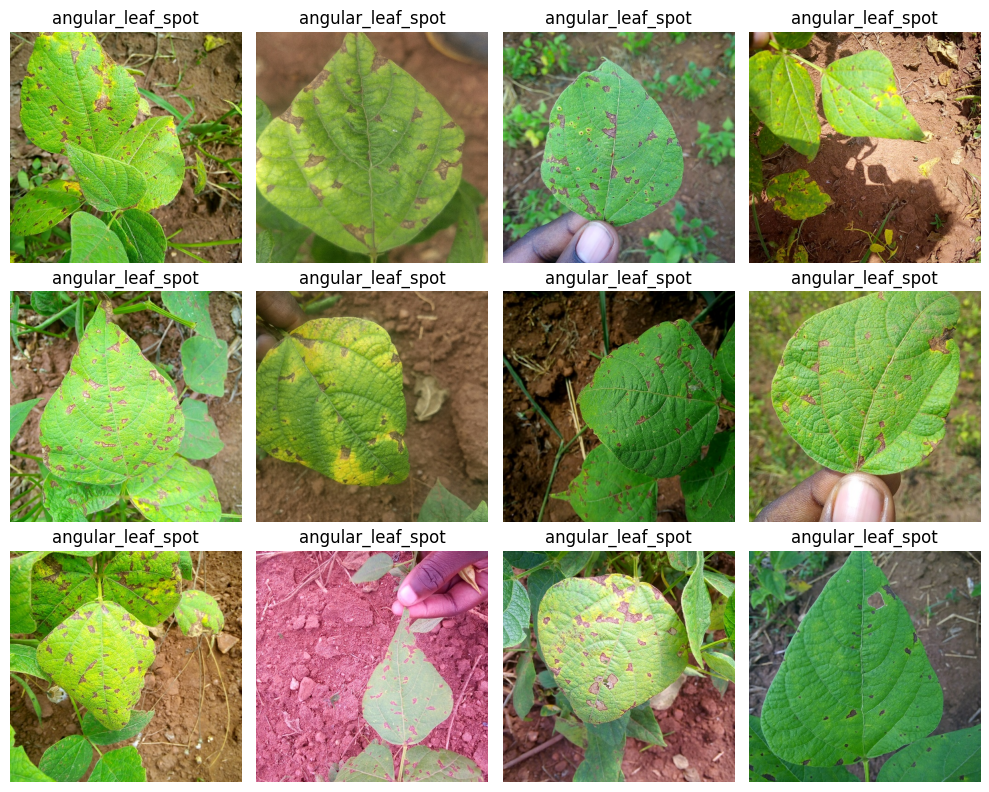

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(10,8))
for ax, item in zip(axes.flat, selected[:12]):
    ax.imshow(item["image"])
    ax.set_title(beans_label_names[item["labels"]])
    ax.axis("off")
plt.tight_layout()
plt.show()

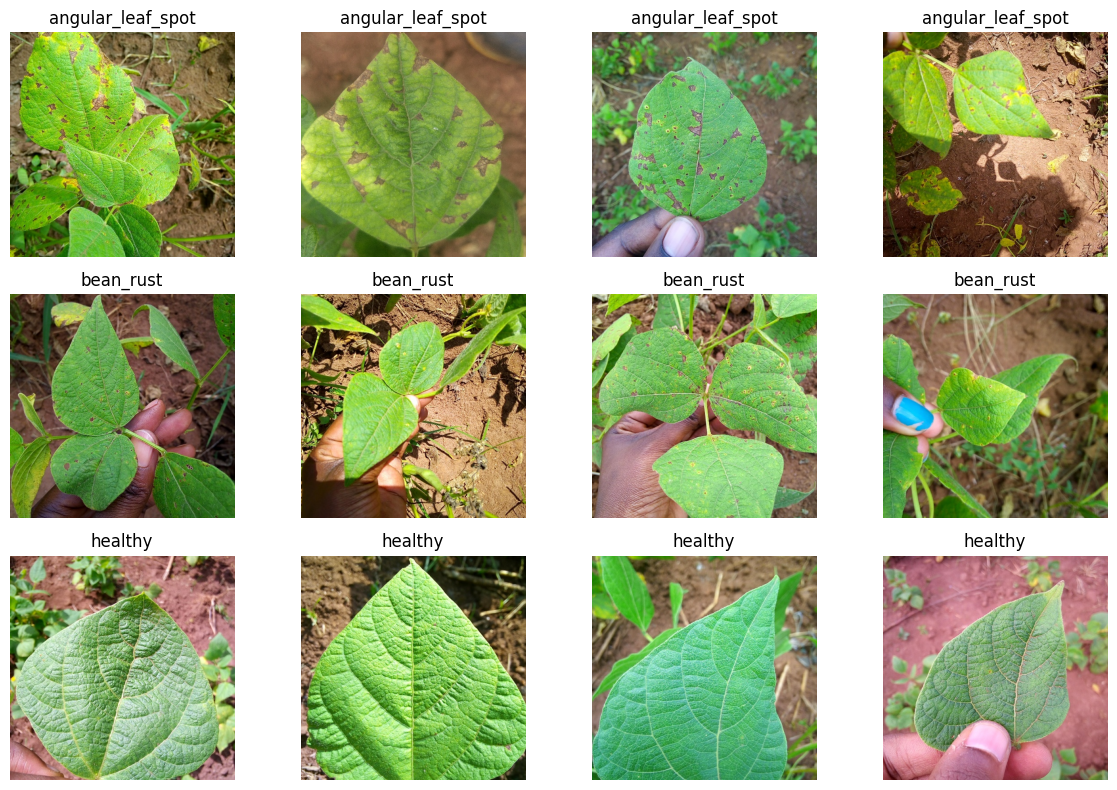

In [ ]:
# 4 imagens de exemplo para cada classe
n_examples = 4

fig, axes = plt.subplots(
    len(beans_label_names),
    n_examples,
    figsize=(12, 8)
)

for class_id, class_name in enumerate(beans_label_names):

    # Seleciona imagens desta classe
    class_items = [
        item for item in selected
        if item["labels"] == class_id
    ]

    # Mostra as primeiras n_examples
    for j in range(n_examples):

        item = class_items[j]

        axes[class_id, j].imshow(item["image"])
        axes[class_id, j].axis("off")

        # Coloca o nome da classe apenas no título
        axes[class_id, j].set_title(class_name)

plt.tight_layout()
plt.show()

### 3.3 Extraindo embeddings com DINOv2

Não faremos fine-tuning. O modelo será usado apenas como extrator de representação.

In [ ]:
import torch
from transformers import AutoImageProcessor, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

image_model_name = "facebook/dinov2-small"
image_processor = AutoImageProcessor.from_pretrained(image_model_name)
image_model = AutoModel.from_pretrained(image_model_name).to(device)
image_model.eval()

Device: cuda


In [ ]:
def extract_image_embeddings(items, batch_size=16):
    embeddings = []
    labels = []

    for start in range(0, len(items), batch_size):
        batch = items[start:start+batch_size]
        images = [item["image"].convert("RGB") for item in batch]
        y = [item["labels"] for item in batch]

        inputs = image_processor(images=images, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = image_model(**inputs)
            emb = outputs.pooler_output

        embeddings.append(emb.cpu().numpy())
        labels.extend(y)

    return np.vstack(embeddings), np.array(labels)

X_img, y_img = extract_image_embeddings(selected)
print("Formato dos embeddings:", X_img.shape)

Formato dos embeddings: (120, 384)


### 3.4 Convertendo embeddings para DataFrame

Agora voltamos ao mundo tabular: **amostras × features**.

In [ ]:
img_feature_names = [f"f_{i:03d}" for i in range(X_img.shape[1])]

df_img = pd.DataFrame(X_img, columns=img_feature_names)
df_img["sample_id"] = df_img.index # Add a unique identifier
df_img["label"] = y_img
df_img["class_name"] = [beans_label_names[i] for i in y_img]

# Add original dataset split as metadata
# Assuming all 'selected' items are from the 'train' split after previous modification
df_img['original_split'] = 'train'

# Reorder columns to have id and metadata at the beginning
df_img = df_img[['sample_id', 'label', 'class_name', 'original_split'] + img_feature_names]

df_img.head()

,f_000,f_001,f_002,f_003,f_004,f_005,f_006,f_007,f_008,f_009,f_010,f_011,f_012,f_013,f_014,f_015,f_016,f_017,f_018,f_019,f_020,f_021,f_022,f_023,f_024,f_025,f_026,f_027,f_028,f_029,f_030,f_031,f_032,f_033,f_034,f_035,f_036,f_037,f_038,f_039,f_040,f_041,f_042,f_043,f_044,f_045,f_046,f_047,f_048,f_049,...,f_336,f_337,f_338,f_339,f_340,f_341,f_342,f_343,f_344,f_345,f_346,f_347,f_348,f_349,f_350,f_351,f_352,f_353,f_354,f_355,f_356,f_357,f_358,f_359,f_360,f_361,f_362,f_363,f_364,f_365,f_366,f_367,f_368,f_369,f_370,f_371,f_372,f_373,f_374,f_375,f_376,f_377,f_378,f_379,f_380,f_381,f_382,f_383,label,class_name
0,2.968932,0.269039,-1.082886,3.924317,-1.580633,1.530982,0.886239,0.410058,2.292624,0.957554,4.352075,-1.154888,0.668255,1.480324,-1.849427,-4.190108,-1.903686,6.514801,1.481264,7.645980,-0.748169,5.311494,-0.867737,-0.674936,-0.841009,-2.056847,-2.633327,-1.293771,-0.714658,-1.862787,1.047115,-0.364035,1.395339,-1.021122,4.762890,-2.543814,-0.560833,-5.215659,-0.687100,-2.369545,-1.960393,-0.494697,1.370465,0.526104,-2.404426,-1.441187,0.087644,2.073954,-5.502596,1.466210,...,-3.531526,0.662572,-4.066810,-1.098485,-0.655156,-2.255959,-0.495070,2.681697,-1.892443,-1.007293,3.884513,-3.004023,-0.398267,2.260755,-4.464904,1.633994,-0.658724,-3.023035,-0.926609,-3.414075,-0.674995,-0.499142,-1.979731,1.277893,-0.120338,-0.854648,-1.755974,0.767045,2.902769,-0.574656,-3.228184,-2.901730,1.580280,-0.748160,5.092413,-0.299475,-1.995671,0.498359,-2.824112,-0.830019,1.591385,1.494052,2.354624,1.187541,1.766923,0.542024,4.198117,-1.294471,0,angular_leaf_spot
1,4.030244,-1.505872,-1.082233,3.680367,-0.664197,0.930553,2.815361,-2.520172,-0.607150,4.108129,2.233734,-4.587995,2.360381,0.585082,1.325695,-3.885330,-1.556726,7.247227,0.546471,5.990471,-0.231876,5.395988,-3.481431,-1.547343,-0.658564,-1.883978,-1.846269,0.484032,-1.318779,-3.634516,2.135097,1.677644,0.585356,-2.701739,4.065250,-2.107091,0.913325,-3.624730,-1.502745,-2.510852,-1.144937,1.173191,2.179479,-0.567825,-2.009903,-0.368442,-2.307777,-0.572131,-6.990251,2.547497,...,-3.391539,4.341014,-1.443626,-2.546734,0.287954,-0.471203,3.743345,0.008524,-0.013429,-0.231730,3.238212,-0.523624,-3.065428,1.510347,-2.121526,2.978377,-1.634744,-3.012524,-1.203971,0.296046,-1.359709,1.328498,1.834433,0.619489,1.460518,-2.869111,-3.290186,1.844281,3.190285,-0.296163,-4.869602,-1.494457,-0.010238,-3.346884,0.478437,-0.283456,0.126327,-1.039274,-6.259969,-0.486272,0.142283,1.659839,2.820896,3.255965,-0.356719,2.205427,6.677022,0.985249,0,angular_leaf_spot
2,2.304728,-0.683455,-1.138122,2.723953,-2.287553,2.347672,1.909114,0.177144,2.003909,2.336989,4.003444,-5.019677,1.939662,0.753237,-1.698041,-5.073191,-2.310773,5.586121,-0.051316,8.120552,0.602840,4.159861,0.749084,-1.124431,-0.903088,-3.142021,-1.541742,-1.042390,-0.919139,-2.926998,0.189261,-0.419972,0.307209,-1.712626,4.940939,-2.027070,-2.488605,-3.970394,-1.030143,-2.269034,1.801519,-0.790593,1.131498,-2.042882,-2.348337,0.739365,-0.276412,1.577342,-4.633365,2.388536,...,-4.176099,0.999738,-2.373052,-1.257461,0.296176,-0.500053,4.116155,-0.698807,-0.181420,-0.202708,0.950617,-2.587573,-1.526188,0.514128,-3.305307,0.810673,-1.178486,-3.915219,-0.017832,2.032358,-0.701152,0.523612,0.330073,1.574609,-0.719672,-0.894985,-2.070555,0.888357,2.494878,0.179704,-3.327472,-3.112988,0.687177,-0.329417,2.927633,2.532369,0.347000,0.440922,-4.963335,-1.147359,2.184532,1.516572,1.544074,2.400926,0.880013,3.388037,5.908508,0.006054,0,angular_leaf_spot
3,1.045042,-0.012043,0.014272,2.930547,1.879110,0.266665,1.052750,0.806572,-1.283597,2.058678,-0.686655,-2.638540,1.417210,1.472605,-0.939091,-3.581250,0.852065,4.198655,2.372450,8.017805,-0.425617,4.563882,-3.014500,-1.020908,-1.518774,-0.323644,-1.678207,2.649199,-1.910969,-1.972866,1.239948,0.767097,1.753538,-0.142702,2.783811,-3.540850,-0.899631,-6.879013,0.602539,-0.791391,-0.720349,0.263320,0.271549,-0.634061,0.527544,0.229943,1.701706,-1.384895,-8.572620,-0.442495,...,-2.626204,2.920344,-1.64202

# 4. EDA dos embeddings de imagem

Com centenas de features, visualizações diretas ficam difíceis.

Vamos usar PCA apenas como ferramenta de inspeção.

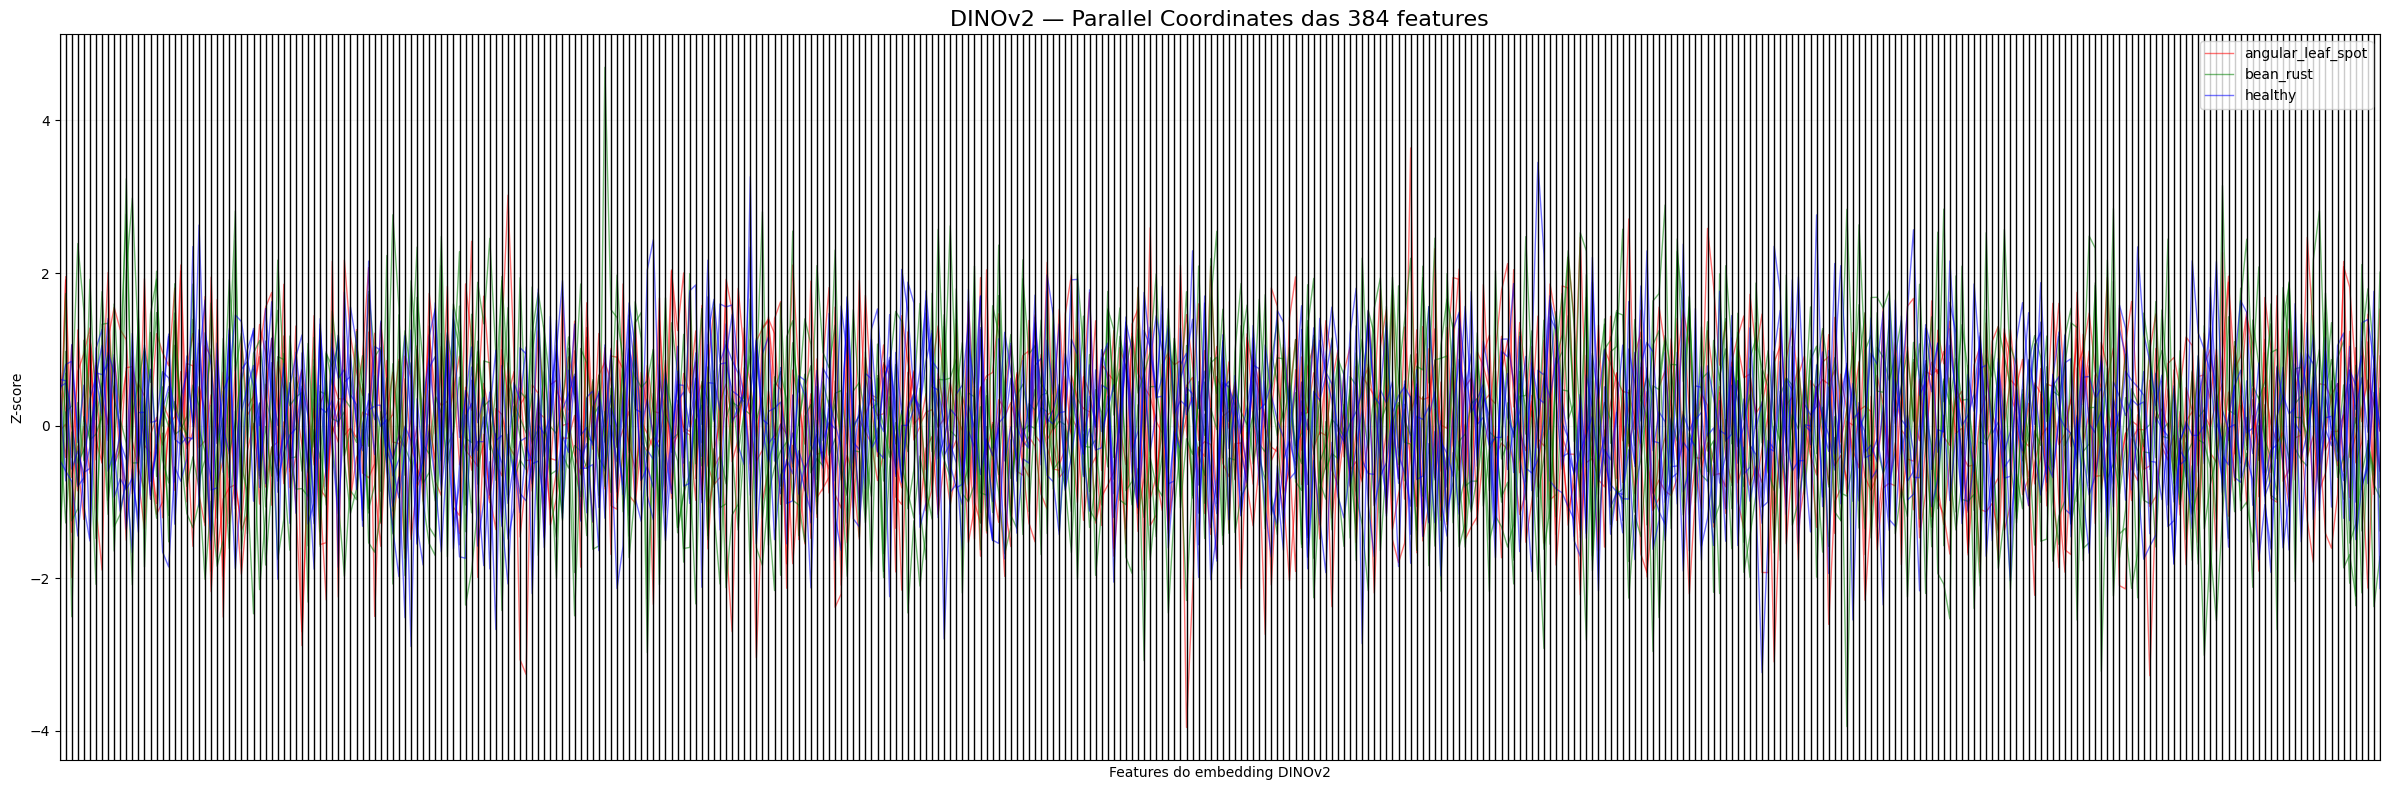

In [ ]:
from pandas.plotting import parallel_coordinates
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Padronizar as 384 features
X_img_scaled = StandardScaler().fit_transform(X_img)



# Criar DataFrame
feature_names = [f"f{i+1}" for i in range(X_img_scaled.shape[1])]

df_parallel_img = pd.DataFrame(
    X_img_scaled,
    columns=feature_names
)

# Converter IDs das classes para nomes
df_parallel_img["class_name"] = [
    beans_label_names[int(label)]
    for label in y_img
]

# --------------------------------------------------
# Selecionar poucas imagens por classe
# para o gráfico não ficar COMPLETAMENTE impossível
# --------------------------------------------------

n_samples_per_class = 5

parts = []

for class_name, group in df_parallel_img.groupby("class_name"):
    parts.append(
        group.sample(
            min(len(group), n_samples_per_class),
            random_state=RANDOM_STATE
        )
    )

sample_parallel_img = pd.concat(parts).reset_index(drop=True)

# --------------------------------------------------
# Parallel Coordinates com TODAS as 384 features
# --------------------------------------------------

plt.figure(figsize=(24, 8))

parallel_coordinates(
    sample_parallel_img,
    class_column="class_name",
    color=["red", "green", "blue"],
    alpha=0.55,
    linewidth=1.0
)

plt.title(
    "DINOv2 — Parallel Coordinates das 384 features",
    fontsize=16
)

plt.xlabel("Features do embedding DINOv2")
plt.ylabel("Z-score")

# Não mostrar os 384 nomes porque ficaria ilegível
plt.xticks([])

plt.grid(alpha=0.15)

plt.tight_layout()
plt.show()

> Complicado de enxergar essas 384 features de uma vez, certo? Talvez poderiamos olhar por janela de 20 em 20 features... mas nao teriamos uma noção global das features. Ou escolher 20 features aleatoriamente, como abaixo:

Features selecionadas:
['f_031', 'f_032', 'f_035', 'f_048', 'f_075', 'f_159', 'f_161', 'f_172', 'f_195', 'f_197', 'f_240', 'f_259', 'f_271', 'f_277', 'f_283', 'f_287', 'f_298', 'f_317', 'f_321', 'f_366']


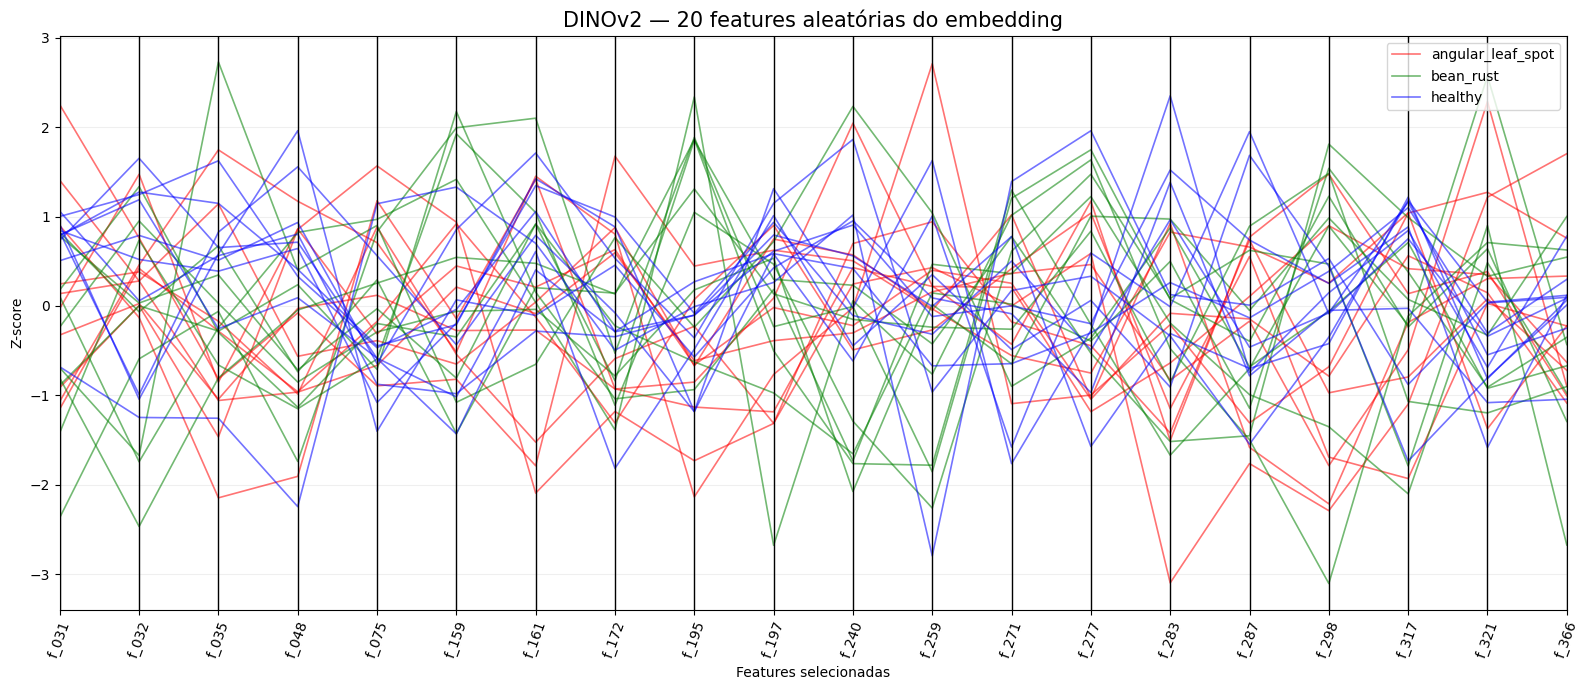

In [ ]:
from pandas.plotting import parallel_coordinates
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Escolher aleatoriamente 20 das 384 features
# --------------------------------------------------

rng = np.random.default_rng(42)

selected_feature_idx = rng.choice(
    X_img_scaled.shape[1],
    size=20,
    replace=False
)

# Ordenar apenas para facilitar a leitura
selected_feature_idx = np.sort(selected_feature_idx)

selected_feature_names = [
    f"f_{i:03d}" for i in selected_feature_idx
]

print("Features selecionadas:")
print(selected_feature_names)


# --------------------------------------------------
# 2. Criar DataFrame apenas com essas 20 features
# --------------------------------------------------

df_parallel_20 = pd.DataFrame(
    X_img_scaled[:, selected_feature_idx],
    columns=selected_feature_names
)

df_parallel_20["class_name"] = [
    beans_label_names[int(label)]
    for label in y_img
]


# --------------------------------------------------
# 3. Selecionar algumas imagens de cada classe
# --------------------------------------------------

n_samples_per_class = 10

parts = []

for class_name, group in df_parallel_20.groupby("class_name"):

    parts.append(
        group.sample(
            min(len(group), n_samples_per_class),
            random_state=RANDOM_STATE
        )
    )

sample_parallel_20 = pd.concat(parts).reset_index(drop=True)


# --------------------------------------------------
# 4. Parallel Coordinates
# --------------------------------------------------

plt.figure(figsize=(16, 7))

parallel_coordinates(
    sample_parallel_20,
    class_column="class_name",
    color=["red", "green", "blue"],
    alpha=0.55,
    linewidth=1.2
)

plt.title(
    "DINOv2 — 20 features aleatórias do embedding",
    fontsize=15
)

plt.xlabel("Features selecionadas")
plt.ylabel("Z-score")

plt.xticks(rotation=70)

plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Agora vamos de PCA, um algoritmo de aprendizado de máquina para a redução de dimensionalidade.

In [ ]:
X_img_scaled = StandardScaler().fit_transform(X_img)

pca_img = PCA(n_components=8, random_state=RANDOM_STATE)
X_img_pca8 = pca_img.fit_transform(X_img_scaled)

print("Variância explicada acumulada (8 PCs):",
      pca_img.explained_variance_ratio_.sum())

Variância explicada acumulada (8 PCs): 0.5023185


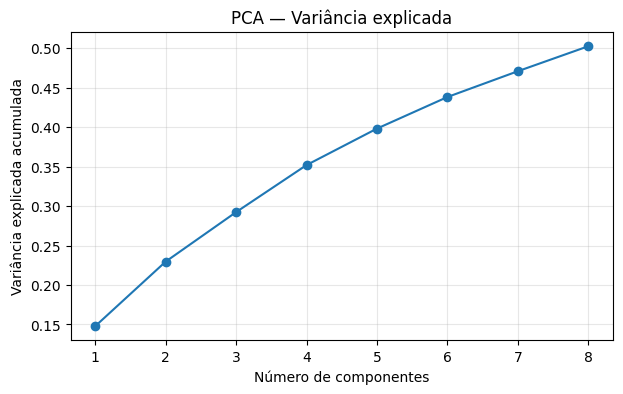

In [ ]:
var_acumulada = np.cumsum(
    pca_img.explained_variance_ratio_
)

plt.figure(figsize=(7,4))

plt.plot(
    range(1, 9),
    var_acumulada,
    marker="o"
)

plt.xlabel("Número de componentes")
plt.ylabel("Variância explicada acumulada")
plt.title("PCA — Variância explicada")
plt.grid(alpha=0.3)

plt.show()

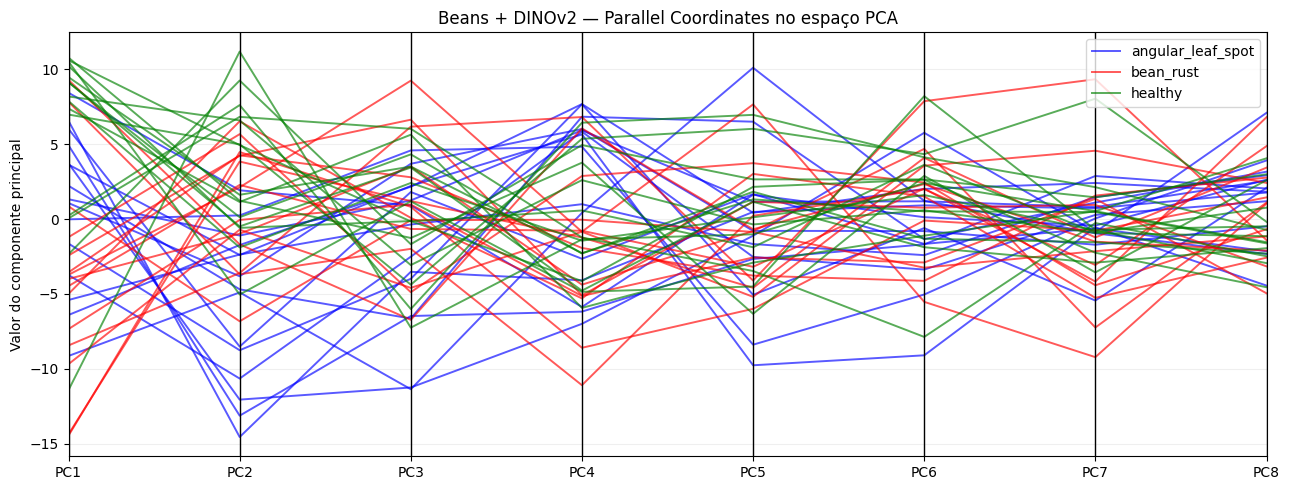

In [ ]:
df_img_pc = pd.DataFrame(
    X_img_pca8,
    columns=[f"PC{i+1}" for i in range(8)]
)

df_img_pc["class_name"] = df_img["class_name"].values


parts = []

for class_name, group in df_img_pc.groupby("class_name"):
    parts.append(
        group.sample(
            min(len(group), 15),
            random_state=RANDOM_STATE
        )
    )

sample_pc = pd.concat(parts).reset_index(drop=True)


plt.figure(figsize=(13, 5))

parallel_coordinates(
    sample_pc,
    class_column="class_name",
    color=["blue", "red", "green"],
    alpha=0.65,
    linewidth=1.4
)

plt.title("Beans + DINOv2 — Parallel Coordinates no espaço PCA")
plt.ylabel("Valor do componente principal")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 4.1 PCA em 3 dimensões

> **Pergunta:** as classes parecem separadas?

In [ ]:
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Padronização das features do embedding
X_img_scaled = StandardScaler().fit_transform(X_img)

# 2. PCA: reduzir de 384 para 3 dimensões
pca_img_3d = PCA(n_components=3)

X_img_pca3 = pca_img_3d.fit_transform(X_img_scaled)

# Variância explicada por componente
print("Variância explicada:")
for i, var in enumerate(pca_img_3d.explained_variance_ratio_):
    print(f"PC{i+1}: {var*100:.2f}%")

print(
    f"\nVariância explicada acumulada: "
    f"{pca_img_3d.explained_variance_ratio_.sum()*100:.2f}%"
)

# 3. DataFrame para o Plotly
df_pca3 = pd.DataFrame(
    X_img_pca3,
    columns=["PC1", "PC2", "PC3"]
)

df_pca3["class_name"] = [
    beans_label_names[int(label)]
    for label in y_img
]

# 4. Scatter plot 3D
fig = px.scatter_3d(
    df_pca3,
    x="PC1",
    y="PC2",
    z="PC3",
    color="class_name",

    color_discrete_map={
        "angular_leaf_spot": "blue",
        "bean_rust": "red",
        "healthy": "green"
    },

    opacity=0.75,

    title="Beans + DINOv2 — PCA em 3 dimensões"
)

# Aumentar os pontos
fig.update_traces(
    marker=dict(size=6)
)

fig.update_layout(
    width=900,
    height=700
)

fig.show()

Variância explicada:
PC1: 14.78%
PC2: 8.18%
PC3: 6.27%

Variância explicada acumulada: 29.23%


### 4.2 Procurando imagens atípicas no espaço de features

In [ ]:
iso_img = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
img_outlier_pred = iso_img.fit_predict(X_img_scaled)

outlier_positions = np.where(img_outlier_pred == -1)[0]
print("Candidatos a outlier:", len(outlier_positions))

In [ ]:
if len(outlier_positions) > 0:
    n_show = min(8, len(outlier_positions))
    fig, axes = plt.subplots(2, 4, figsize=(10,5))
    for ax in axes.flat:
        ax.axis("off")
    for ax, pos in zip(axes.flat, outlier_positions[:n_show]):
        ax.imshow(selected[pos]["image"])
        ax.set_title(beans_label_names[selected[pos]["labels"]])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Discussão

- Esses outliers parecem realmente diferentes visualmente?
- São erros ou exemplos legítimos difíceis?
- Um ponto próximo de outra classe pode indicar ruído, erro de rótulo, ambiguidade real ou representação inadequada?

# 5. Texto: de sentenças para features com Sentence Transformers

## Dataset: AG News

Classes:

- World
- Sports
- Business
- Sci/Tech

## Pergunta

**Os embeddings semânticos organizam as notícias de acordo com seus temas?**

Fluxo:

**Texto → Sentence Transformer → embedding**

In [ ]:
from datasets import load_dataset

# Try updating the libraries first if this error persists
# !pip install -U datasets huggingface_hub

ag = load_dataset("ag_news")
ag

HfUriError: Invalid HF URI 'hf://datasets/ag_news@eb185aade064a813bc0b7f42de02595523103ca4/.huggingface.yaml'. Repository id must be 'namespace/name', got 'ag_news'.

In [ ]:
!pip install -U datasets huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 793.2/793.2 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 16.2 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.27.0
    Uninstalling huggingface_hub-1.27.0:
      Successfully uninstalled huggingface_hub-1.27.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0


### 5.1 Amostragem estratificada

In [ ]:
N_TEXT_PER_CLASS = 120

text_items = []
for label_id in sorted(set(ag["train"]["label"])):
    subset = ag["train"].filter(lambda x: x["label"] == label_id)
    subset = subset.shuffle(seed=RANDOM_STATE).select(range(N_TEXT_PER_CLASS))
    text_items.extend([subset[i] for i in range(len(subset))])

ag_label_names = ["World", "Sports", "Business", "Sci/Tech"]

df_text_raw = pd.DataFrame({
    "text": [x["text"] for x in text_items],
    "label": [x["label"] for x in text_items],
})
df_text_raw["class_name"] = df_text_raw["label"].map(dict(enumerate(ag_label_names)))

df_text_raw.head()

### 5.2 EDA do texto bruto

In [ ]:
df_text_raw["n_chars"] = df_text_raw["text"].str.len()
df_text_raw["n_words"] = df_text_raw["text"].str.split().str.len()

display(df_text_raw[["n_chars", "n_words"]].describe())

print("Duplicatas de texto:", df_text_raw["text"].duplicated().sum())
print("Textos vazios:", (df_text_raw["text"].str.strip() == "").sum())

display(df_text_raw["class_name"].value_counts())

### 5.3 Gerando embeddings textuais

In [ ]:
from sentence_transformers import SentenceTransformer

text_model_name = "sentence-transformers/all-MiniLM-L6-v2"
text_model = SentenceTransformer(text_model_name, device=device)

X_text = text_model.encode(
    df_text_raw["text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=False
)

print("Formato dos embeddings:", X_text.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

NameError: name 'df_text_raw' is not defined

In [ ]:
text_feature_names = [f"f_{i:03d}" for i in range(X_text.shape[1])]

df_text = pd.DataFrame(X_text, columns=text_feature_names)
df_text["label"] = df_text_raw["label"].values
df_text["class_name"] = df_text_raw["class_name"].values

df_text.head()

# 6. EDA dos embeddings de texto

In [ ]:
X_text_scaled = StandardScaler().fit_transform(X_text)

pca_text8 = PCA(n_components=8, random_state=RANDOM_STATE)
X_text_pca8 = pca_text8.fit_transform(X_text_scaled)

df_text_pc = pd.DataFrame(
    X_text_pca8,
    columns=[f"PC{i+1}" for i in range(8)]
)
df_text_pc["class_name"] = df_text["class_name"].values

parts = []
for class_name, group in df_text_pc.groupby("class_name"):
    parts.append(group.sample(min(len(group), 12), random_state=RANDOM_STATE))
sample_text_pc = pd.concat(parts).reset_index(drop=True)

plt.figure(figsize=(13,5))
parallel_coordinates(sample_text_pc, "class_name", alpha=0.3)
plt.title("AG News + MiniLM — Parallel Coordinates no espaço PCA")
plt.tight_layout()
plt.show()

In [ ]:
pca_text2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_text_2d = pca_text2.fit_transform(X_text_scaled)

plt.figure(figsize=(8,6))
for class_id, class_name in enumerate(ag_label_names):
    mask = df_text["label"].values == class_id
    plt.scatter(X_text_2d[mask,0], X_text_2d[mask,1], alpha=0.55, label=class_name)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("AG News + MiniLM — PCA 2D")
plt.legend()
plt.show()

### Discussão

- Quais classes parecem mais separadas?
- Quais se sobrepõem?
- PCA preserva toda a estrutura semântica?
- Um espaço pouco separável em 2D pode ainda ser classificável em alta dimensão?

# 7. Simulando problemas de qualidade em embeddings

Problemas também podem surgir depois do processamento:

- vetores ausentes;
- duplicatas;
- ruído;
- rótulos incorretos.

In [ ]:
df_text_dirty = df_text.copy()

# Missing
for col in text_feature_names[:3]:
    idx = np.random.choice(df_text_dirty.index, size=8, replace=False)
    df_text_dirty.loc[idx, col] = np.nan

# Duplicatas
df_text_dirty = pd.concat([df_text_dirty, df_text_dirty.iloc[:5]], ignore_index=True)

# Label noise
flip_idx = np.random.choice(df_text_dirty.index[:-5], size=12, replace=False)
df_text_dirty.loc[flip_idx, "label"] = np.random.randint(0, 4, size=len(flip_idx))
df_text_dirty["class_name"] = df_text_dirty["label"].map(dict(enumerate(ag_label_names)))

print("Missing nas primeiras features:")
display(df_text_dirty[text_feature_names[:6]].isna().sum())

print("Duplicatas completas:", df_text_dirty.duplicated().sum())

### Pergunta

Um embedding com `NaN` provavelmente foi causado pelo fenômeno real ou pelo pipeline?

**Problemas de qualidade podem surgir no dado bruto ou durante o processamento.**

# 8. Classificação simples como teste da representação

Hipótese:

> **Se as representações contêm informação discriminativa, um classificador simples deve alcançar desempenho razoável.**

Usaremos Regressão Logística para reduzir a interferência da complexidade do classificador.

## 8.1 Wine

In [ ]:
X_wine = StandardScaler().fit_transform(df_wine[feature_cols])
y_wine = df_wine["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X_wine, y_wine, test_size=0.25, stratify=y_wine, random_state=RANDOM_STATE
)

clf = LogisticRegression(max_iter=3000)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print(classification_report(y_test, pred, target_names=list(wine.target_names)))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=list(wine.target_names), xticks_rotation=45
)
plt.title("Wine — Logistic Regression")
plt.show()

## 8.2 Beans + DINOv2

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_img_scaled, y_img, test_size=0.25, stratify=y_img, random_state=RANDOM_STATE
)

clf = LogisticRegression(max_iter=3000)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print(classification_report(y_test, pred, target_names=beans_label_names))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=beans_label_names, xticks_rotation=45
)
plt.title("Beans + DINOv2 — Logistic Regression")
plt.show()

## 8.3 AG News + MiniLM

In [ ]:
y_text = df_text["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X_text_scaled, y_text, test_size=0.25, stratify=y_text, random_state=RANDOM_STATE
)

clf = LogisticRegression(max_iter=3000)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print(classification_report(y_test, pred, target_names=ag_label_names))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=ag_label_names, xticks_rotation=45
)
plt.title("AG News + MiniLM — Logistic Regression")
plt.show()

# 9. Síntese

| Modalidade | Dado bruto | Representação usada na EDA | Problema |
|---|---|---|---|
| Tabular | atributos químicos | features originais | classificação de vinho |
| Imagem | pixels | DINOv2 embeddings | doença da folha |
| Texto | notícia | MiniLM embeddings | tema da notícia |

## Mensagem central

**Pergunta → representação → qualidade → exploração → hipótese → classificação**

### Perguntas finais

1. O que significa uma “boa feature”?
2. Um embedding excelente dispensa EDA?
3. Outliers em embeddings são mais difíceis de interpretar que outliers em atributos físicos?
4. Como detectar um label errado em imagem ou texto?
5. Em que momento uma visualização 2D pode induzir conclusões erradas?

# 10. Atividade para os alunos

Escolha **uma** modalidade e produza um pequeno relatório com:

1. Pergunta de investigação.
2. Unidade de análise.
3. Features utilizadas.
4. Uma análise de qualidade.
5. Uma visualização univariada ou multivariada.
6. Uma projeção PCA 2D.
7. Uma hipótese sobre separabilidade das classes.
8. Um teste com Regressão Logística.
9. Uma limitação da análise.

## Extensões opcionais

- inserir label noise e medir impacto;
- usar UMAP apenas como extensão;
- comparar Isolation Forest com distância ao centroide;
- identificar possíveis duplicatas semânticas em texto;
- procurar imagens suspeitas de erro de rótulo.

# Referências e recursos

- Oquab et al. — **DINOv2: Learning Robust Visual Features without Supervision**.
- Hugging Face Transformers — documentação do DINOv2.
- Makerere AI Lab — **Beans**.
- **AG News** — benchmark de classificação de tópicos.
- Sentence Transformers — `all-MiniLM-L6-v2`.

> Para fins didáticos, trabalhamos com subconjuntos pequenos para que o notebook execute rapidamente no Google Colab.